## Programmation Quantique

### Nicolas Ollinger et Ioan Todinca
<img style="width:15%; height: auto;" src="img/lifo.png">

#### M2 info, S9 2024/2025

## Descriptif du cours

Ce cours propose de découvrir l'informatique quantique à
travers la <b class="cool">programmation de circuits quantiques</b>. 

Les étudiants sont
invités à <b class="cool">construire des circuits</b> et à <b class="cool">simuler leur exécution</b> pour
comprendre ce que propose la technologie quantique actuelle et comment
elle se distingue des modèles classiques de <b class="cool">calcul booléen</b>. Cette
approche expérimentale permettra ensuite de présenter plus précisemment
les promesses algorithmiques et les enjeux actuels de cette technologie.

L'évaluation prend la forme d'un contrôle terminal et d'<b class="cool">éléments à réaliser sur machine</b> et à
rendre à l'issu des TPs.

## Plan de bataille

$$
\begin{align*}
\textbf{ARIAS}\quad 10\mathrm{h~} &\textbf{CM} + 10\mathrm{h~} \textbf{TD} + 10\mathrm{h~} \textbf{TP}\\
\textbf{GPEX}\quad 10\mathrm{h~} &\textbf{CM} + \phantom{1}6\mathrm{h~} \textbf{TD}\\
\end{align*}
$$

| Séance | Intervenant | Durée | Programme |
| :-- | :-- | :-: | :-- |
| CM1 | N. Ollinger | __2h__ | *Circuits quantiques et calcul réversible* |
| CM2 | N. Ollinger | __2h__ | *Circuits et calcul quantique, l'algorithme de Bernstein-Vazirani* |
| CM3 | I. Todinca | __2h__ | *Informatique quantique, algorithmes importants* |
| CM4 | I. Todinca | __2h__ | *L'algorithme de recherche quantique de Grover* |
| CM5 | I. Todinca | __2h__ | *Informatique quantique pour informaticien !* |

## Évaluation

$$
\textbf{UE} = \frac13 \textbf{CC} + \frac23 \textbf{CT}
$$

$\textbf{CC}$ : Des notebook Jupyter à compléter et à rendre sur [Celene](https://celene.univ-orleans.fr/course/view.php?id=12816).

Exercices à réaliser à l'aide de Python et de la bibliothèque [Qiskit](https://qiskit.org) (v1.2)

## Circuits quantiques ?

Les ordinateurs quantiques d'aujourd'hui (ou plutôt de demain ?) s'utilisent comme des _coprocesseurs_ : on y fait subir une <b class="cool">transformation unitaire</b> à un <b class="cool">registre de qubits</b> initialement tous à zéro avant d'effectuer des <b class="cool">mesures</b> sur son état.

Les <b class="cool">transformations unitaires</b> sont codées sous forme de circuits et la programmation quantique ressemble à de la <b class="cool">programmation assembleur</b>.

La programmation quantique propose une <b class="cool">nouvelle forme de parallélisme</b>.

<img style="width:100%; height: auto;" src="img/quito1.png">

<img style="width:100%; height: auto;" src="img/quito2.png">

<img style="width:100%; height: auto;" src="img/quito3.png">

## Illustré avec Qiskit

Ce cours est aussi un notebook jupyter téléchargeable et exécutable dans le Cloud dont les exemples sont construits à l'aide de la bibliothèque __[Qiskit](https://qiskit.org)__ qui permet de manipuler des circuits quantiques en Python :
  1. <b class="cool">construire</b> des circuits ;
  2. <b class="cool">exécuter</b> ces circuits localement dans un  simulateur ;
  3. <b class="cool">exécuter</b> ces circuits sur des processeurs quantique (par exemple d'IBM) ;
  4. <b class="cool">analyser</b> les résultats des exécutions.


### Importons le nécessaire

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit.providers.basic_provider import BasicProvider
from qiskit_aer import UnitarySimulator
from qiskit.visualization import plot_histogram
import qiskit.quantum_info as qi
from math import sqrt
import numpy as np

# Un simulateur de circuit complet
sim = BasicProvider().get_backend('basic_simulator')

# Un simulateur calculant la matrice de transformation
usim = UnitarySimulator()

# Afficher un circuit
def draw_circ(circ): display(circ.draw(output='mpl'))
    
# Calculer la matrice d'un circuit
def mat_circ(circ): return usim.run(circ).result().get_unitary()

def show(circ):
    draw_circ(circ)
    display(mat_circ(circ).draw('latex'))

Mais au fait... <b class="cool">C'est quoi un circuit quantique ?</b>

# Un zeste de théorie...

### Circuits booléens classiques

Depuis les travaux de Shannon à la fin des années 30, l'<b class="cool">algèbre booléenne</b> et le système binaire fondent l'électronique numérique.

Un registre de <b class="cool">mémoire classique</b> stocke un vecteur de <b class="cool">bits</b> qui prennent chacun une valeur parmi deux : $0$ ou $1$. Les bits sont indépendants, $n$ bits stockent un valeur parmi $2^n$.

Des <b class="cool">portes logiques</b> réalisant des fonctions logiques ($\operatorname{ET}$, $\operatorname{OU}$, $\operatorname{NON}$) permettent de <b class="cool">calculer efficacement</b> toute fonction booléenne $f : \left\{0,1\right\}^n \longrightarrow \left\{0,1\right\}^m$.

### Un qubit

Un registre de <b class="cool">mémoire quantique</b> est un <b class="cool">système quantique discret fini</b> constitué de <b class="cool">qubits</b>.

Un <b class="cool">bit quantique</b> est une superposition de $0$ et de $1$ :
$$
\alpha \left|0\right> + \beta \left|1\right> \quad\mbox{avec}\quad \alpha, \beta \in \mathbb{C}
\quad\mbox{tels que}\quad |\alpha|^2+|\beta|^2 = 1
$$

Par exemple $\left|0\right>$ ou encore $\frac{1}{\sqrt{2}}\left(\left|0\right>+\left|1\right>\right)$

### Des qubits

Un registre de <b class="cool">$n$ qubits</b> est une superposition de chacun des vecteurs de bits possibles, chacun muni d'une amplitude.

$$
\left|\varphi\right> = \sum_{x\in\{0,1\}^n} \alpha_x\left|x\right> \quad\mbox{tels que}\quad \sqrt{\sum_{x\in\{0,1\}^n}  |\alpha_x|^2} = 1
$$

Par exemple $\frac12\left|1000\right>+\frac12\left|0100\right>+\frac12\left|0010\right>+\frac12\left|0001\right>$

### Produit tensoriel

La <b class="cool">composition</b> de deux registres quantiques s'obtient par l'opérateur bilinéaire de produit tensoriel $\otimes$ qui satisfait $\left|x\right> \otimes \left|y\right> = \left|xy\right>$.

$$
\left|1\right> \otimes \frac{1}{\sqrt{2}}\left(\left|0\right>+\left|1\right>\right) =
\frac{1}{\sqrt{2}}\left(\left|10\right>+\left|11\right>\right)
$$

Contrairement au cas classique, tout registre n'est pas décomposable en sous-registres ! 

Exemple d'état <b class="cool">intriqué</b> : $\frac{1}{\sqrt{2}}\left(\left|00\right>+\left|11\right>\right)$.

## Mesure quantique (observation)

<img style="width=100%; height=auto; margin: auto" src="img/mesure.png" />

## Mesure quantique d'un qubit particulier

Partant d'un état $\left|\varphi\right> = \sum_x \alpha_x\left|x\right>$, si on mesure le qubit numéro $i$, on observe la valeur $r$ avec la probabilité $p_r$ et le système change d'état :

$$
\sum_{x\in\left\{0,1\right\}^n} \alpha_x\left|x\right> \underset{\phantom{blop}p_r\phantom{blop}}{\longrightarrow}
\frac{1}{\sqrt{p_r}} \sum_{x\in\left\{0,1\right\}^n | x_i = r} \alpha_x\left|x\right>
$$
 
$$
\mbox{avec}\quad p_r = \sum_{x\in\left\{0,1\right\}^n | x_i = r}|\alpha_x|^2
$$

## Évolution unitaire

En l'absence de mesure, lorsqu'il est isolé, l'état d'un système quantique évolue de manière <b class="cool">unitaire</b>.

$$
U : \mathbb{C}^{\{0,1\}^n} \rightarrow \mathbb{C}^{\{0,1\}^n}
$$

1. $U$ est linéaire : $$
U\left(\alpha\left|\varphi\right>+\beta\left|\psi\right>\right) = \alpha U\left|\varphi\right>+\beta U\left|\psi\right>\quad;
$$
2. $U$ préserve la norme : $\left\| U\left|\varphi\right> \right\| = \left\| \left|\varphi\right> \right\|$.

## Porte quantique

Un circuit quantique code une <b class="cool">transformation unitaire</b> obtenue par composition de <b class="cool">portes quantiques</b> elles aussi unitaires, donc réversibles, avec autant de qubits en entrée qu'en sortie.
- composition séquentielle : produit de matrices ;
- composition parallèle : produit tensoriel.

Quelle <b class="cool">famille de portes universelles ?</b>

## Portes sur 1 qubit

$$
\begin{array}{clclcl}
X :& \left|0\right> \mapsto \left|1\right> & H :& \left|0\right> \mapsto \frac{\left|0\right>+\left|1\right>}{\sqrt2}  & R_\theta :& \left|0\right> \mapsto \left|0\right>\\
   & \left|1\right> \mapsto \left|0\right> &    & \left|1\right> \mapsto \frac{\left|0\right>-\left|1\right>}{\sqrt2} &  & \left|1\right> \mapsto e^{i\theta}\left|1\right> \\
\end{array}
$$

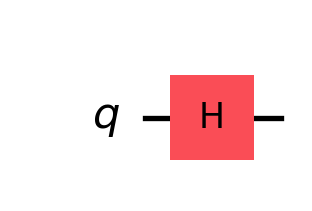

<IPython.core.display.Latex object>

In [2]:
circuit = QuantumCircuit(1)
# remplacer ici le x par h ou t (=r(pi/4)) ou sx (sqrt(x))
circuit.h(0)
show(circuit)

## Portes contrôlées

$$
\begin{array}{cl}
CX :& \left|00\right> \mapsto \left|00\right> \\
   & \left|01\right> \mapsto \left|01\right> \\
   & \left|10\right> \mapsto \left|11\right> \\
   & \left|11\right> \mapsto \left|10\right> \\
\end{array}
$$

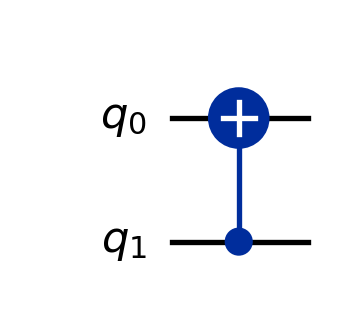

<IPython.core.display.Latex object>

In [3]:
circuit = QuantumCircuit(2)
circuit.cx(1,0)
show(circuit)

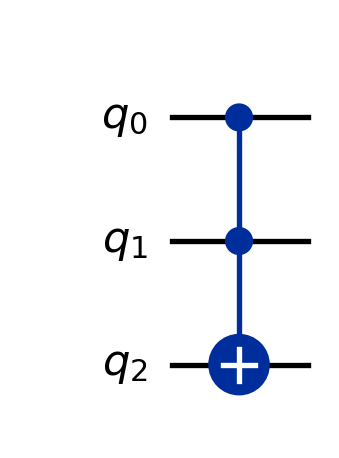

<IPython.core.display.Latex object>

In [4]:
circuit = QuantumCircuit(3)  
circuit.ccx(0,1,2)
show(circuit)

## Universalité

La famille de portes $\left\{H, CX, R_\theta\right\}_{\theta\in[0,2\pi[}$ est <b class="cool">universelle</b> pour les transformations unitaires.

La famille de portes $\left\{H, CX, R_{\frac{\Pi}4}\right\}$ est <b class="cool">approximativement universelle</b> pour les transformations unitaires : elle les réalise avec une erreur $\varepsilon$ souhaitée.

Le <b class="cool">théorème de Solovay-Kitaev</b> nous assure que toutes les familles de portes approximativement universelles le sont <b class="cool">efficacement</b>.

## Compatibilité

Toute fonction classique $f : \{0,1\}^n \rightarrow \{0,1\}^m$ est simulée par un circuit quantique de taille similaire.

$$
\begin{array}{ccccc}
U_f &:& \mathbb{C}^{\{0,1\}^{m+n}} & \rightarrow & \mathbb{C}^{\{0,1\}^{m+n}}\\
    & & \left|x,y\right> & \mapsto & \left|x, f(x)\oplus y \right>
\end{array}
$$

C'est un résultat de <b class="cool">calcul réversible</b>.

## Algorithme quantique

La plupart des <b class="cool">algorithmes quantiques</b> fonctionnent sur le principe suivant :
1. créer une superposition pertinente de qubits à partir de $\left|00\cdots 0\right>$ ;
2. effectuer <b class="cool">en parallèle</b> un calcul classique sur la superposition des entrées ;
3. effectuer une <b class="cool">transformation quantique pertinente</b> ;
4. observer le résultat grâce à des <b class="cool">mesures</b>.

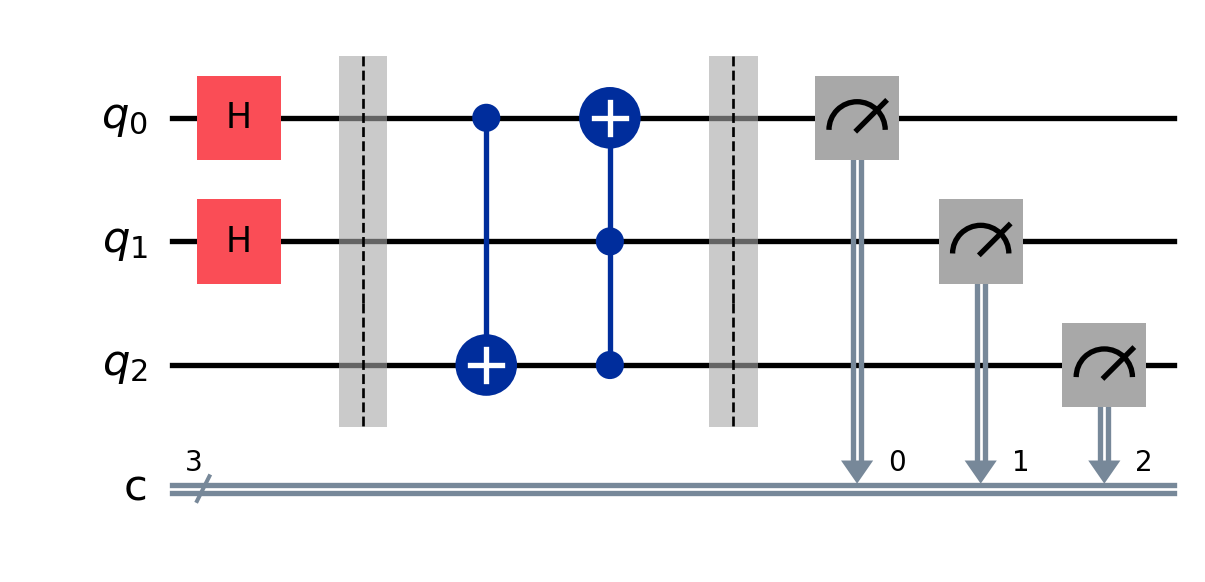

In [5]:
circ = QuantumCircuit(3,3)
for i in range(2): circ.h(i)
circ.barrier()
circ.cx(0,2)
circ.ccx(1,2,0)
circ.barrier()
for i in range(3): circ.measure(i,i)
draw_circ(circ)

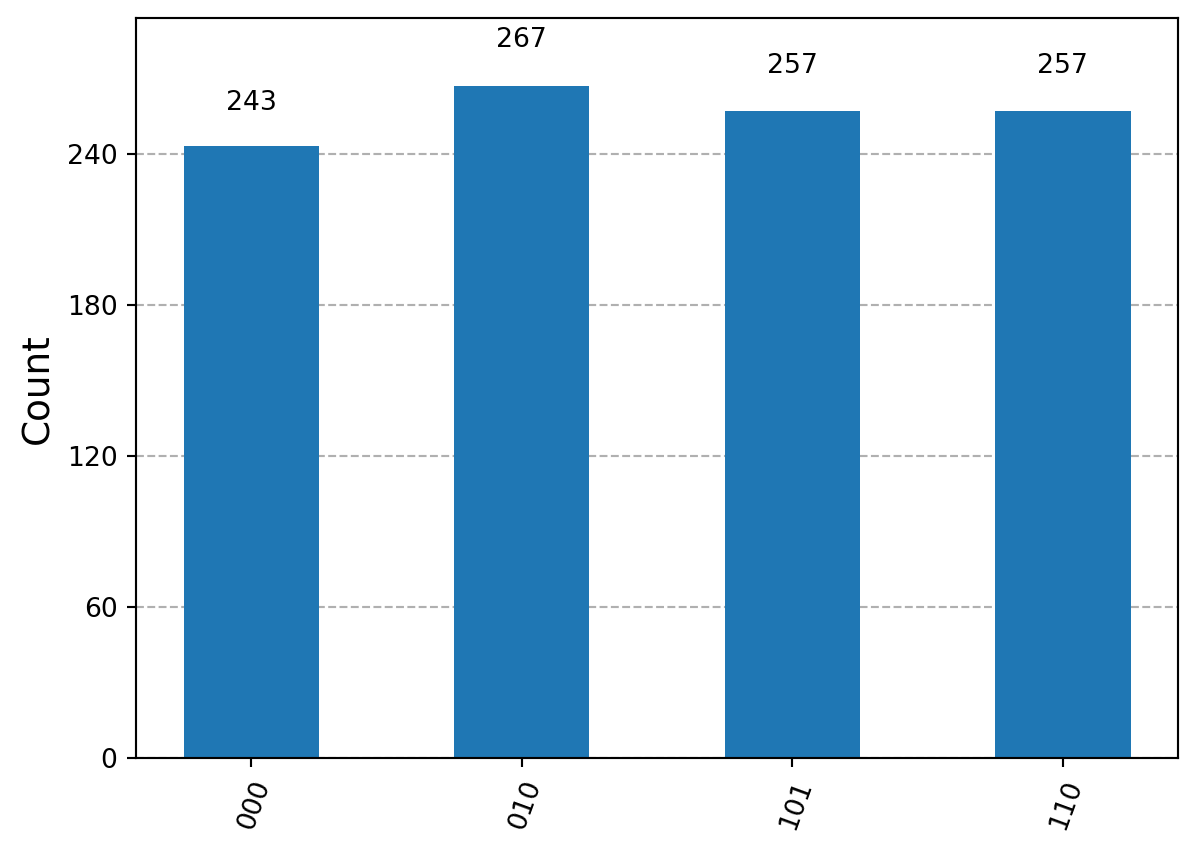

In [6]:
res = sim.run(circ, shots=1024).result()
display(plot_histogram(res.get_counts()))

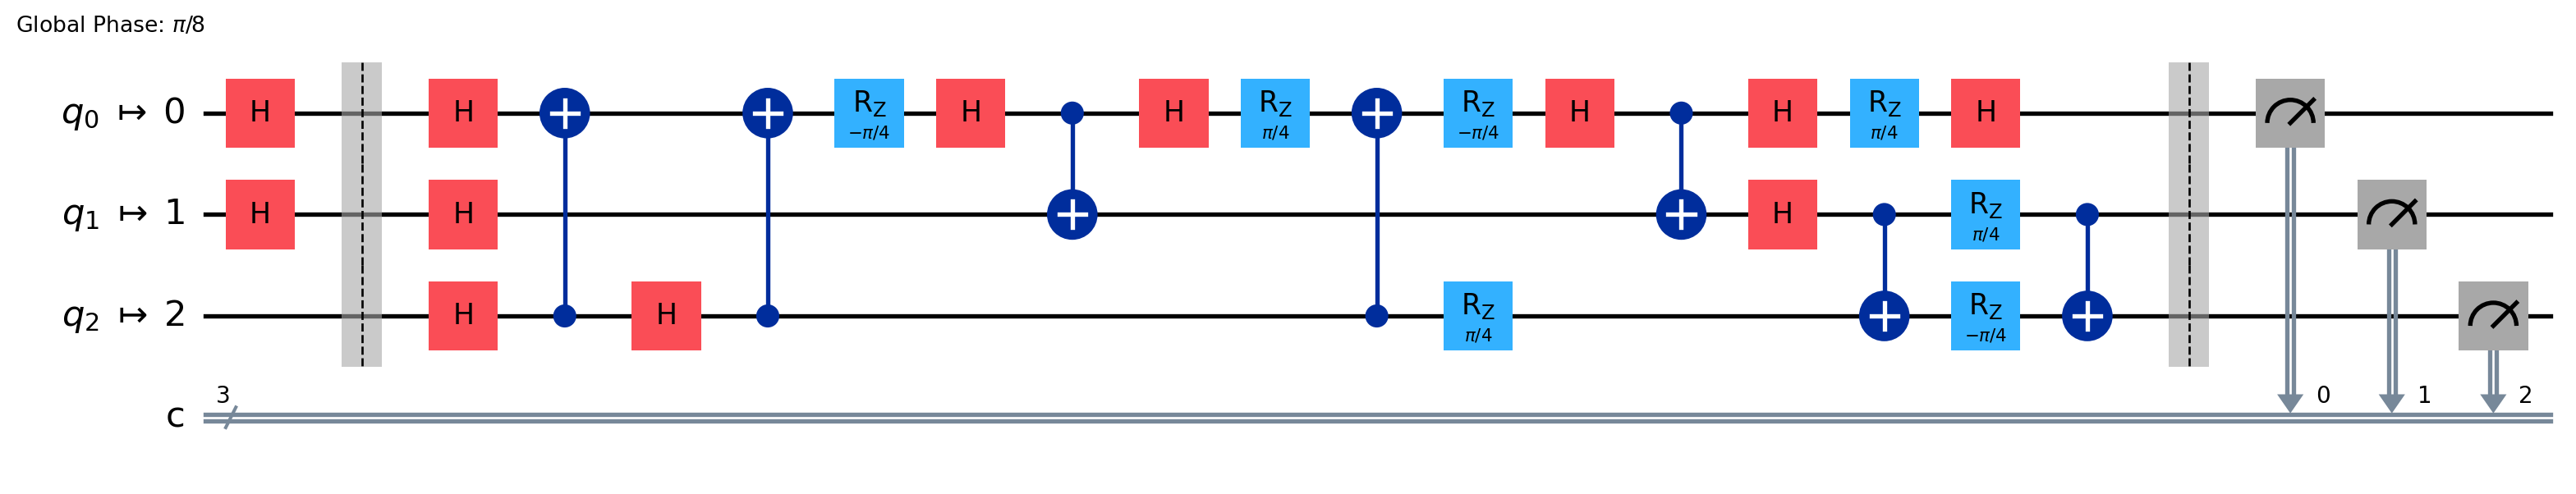

In [7]:
res=transpile(circ,basis_gates=['h','cx', 'rz'], coupling_map = [[0,1],[1,2],[2,0]], optimization_level=1)
draw_circ(res)

# Pour aller plus loin

P. Arrighi et S. Perdrix. _Modèles de calcul quantique_. dans __[Informatique Mathématique, une photographie en 2016](https://www.gdr-ifm.fr/wp-content/uploads/2020/04/recueilEJCIM16-1.pdf)__. CNRS Éditions.

M.A. Nielsen et I.L. Chuang. _Quantum Computation and Quantum Information_. Cambridge Univ. Press, 2000.

__[IBM Q Experience.](https://quantum-computing.ibm.com)__

__[Introduction to Coding Quantum Algorithms: A Tutorial Series Using Qiskit](https://arxiv.org/abs/1903.04359)__